<a href="https://colab.research.google.com/github/OliveiraMatheuus/segmentacao-pluma-sam/blob/main/Modelagem_Computacional.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Instalar o Segment Anything e baixar o modelo (ViT-B é mais leve e rápido para rodar a tempo)
!pip install -q git+https://github.com/facebookresearch/segment-anything.git
!wget -q -nc https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor

  Preparing metadata (setup.py) ... done


Usando dispositivo: cuda


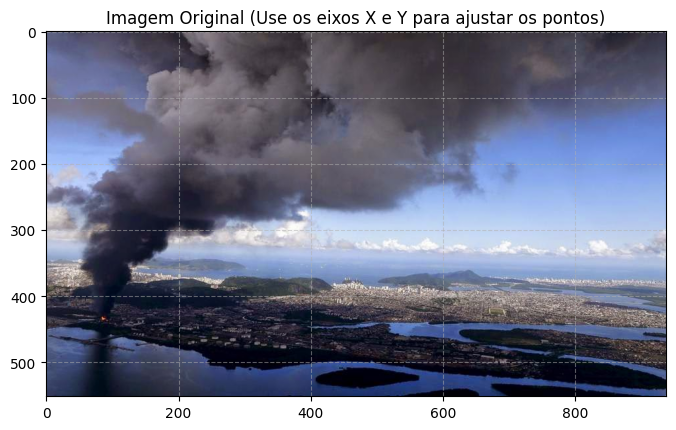

In [ ]:
# Configurar dispositivo (GPU se disponível)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Usando dispositivo: {device}")

sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth")
sam.to(device=device)
predictor = SamPredictor(sam)

# Carregar a imagem
caminho_imagem = "/content/Santos_Abril+2015_NanoPoluição-2092122424.jpg"
image_bgr = cv2.imread(caminho_imagem)
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

# Processar os embeddings da imagem no SAM
predictor.set_image(image_rgb)

# Mostrar imagem com grade de coordenadas para ajudar a escolher os pontos (X, Y)
plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)
plt.title("Imagem Original (Use os eixos X e Y para ajustar os pontos)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
def plotar_resultado(image, mask, titulo, input_points=None, input_labels=None, input_box=None):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(titulo, fontsize=16, fontweight='bold')

    # 1. Imagem Original + Prompts usados
    axes[0].imshow(image)
    axes[0].set_title("1. Imagem Original + Prompts")
    if input_points is not None:
        pos_pts = input_points[input_labels == 1]
        neg_pts = input_points[input_labels == 0]
        if len(pos_pts) > 0:
            axes[0].scatter(pos_pts[:, 0], pos_pts[:, 1], color='lime', marker='*', s=200, edgecolor='black', label='Positivo (Pluma)')
        if len(neg_pts) > 0:
            axes[0].scatter(neg_pts[:, 0], neg_pts[:, 1], color='red', marker='X', s=150, edgecolor='black', label='Negativo (Fundo)')
        axes[0].legend(loc='upper right')
    if input_box is not None:
        x0, y0, x1, y1 = input_box
        axes[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, edgecolor='yellow', facecolor='none', lw=2, label='Bounding Box'))
    axes[0].axis('off')

    # 2. Máscara Binária
    axes[1].imshow(mask, cmap='gray')
    axes[1].set_title("2. Máscara Binária")
    axes[1].axis('off')

    # 3. Máscara Sobreposta à Imagem
    axes[2].imshow(image)
    # Criar sobreposição colorida (vermelho/laranja semitransparente na região da pluma)
    overlay = np.zeros((mask.shape[0], mask.shape[1], 4))
    overlay[mask > 0] = [1.0, 0.2, 0.0, 0.55] # Cor RGBA
    axes[2].imshow(overlay)
    axes[2].set_title("3. Máscara Sobreposta")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

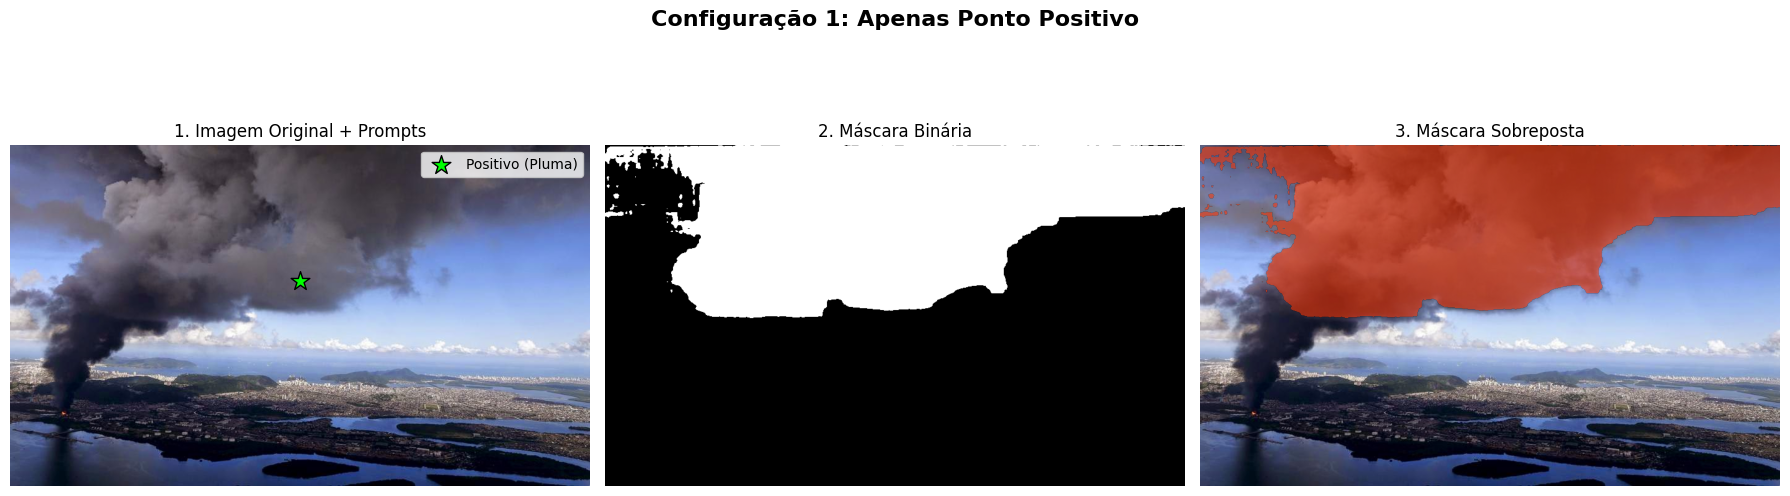

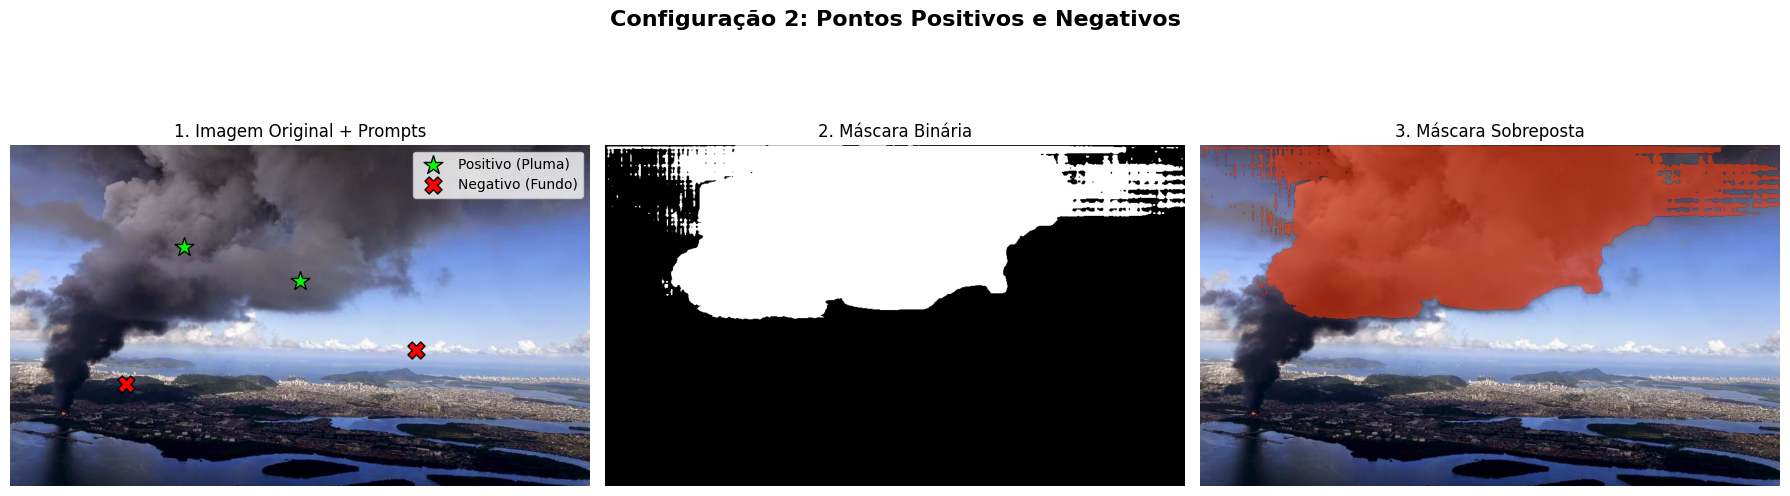

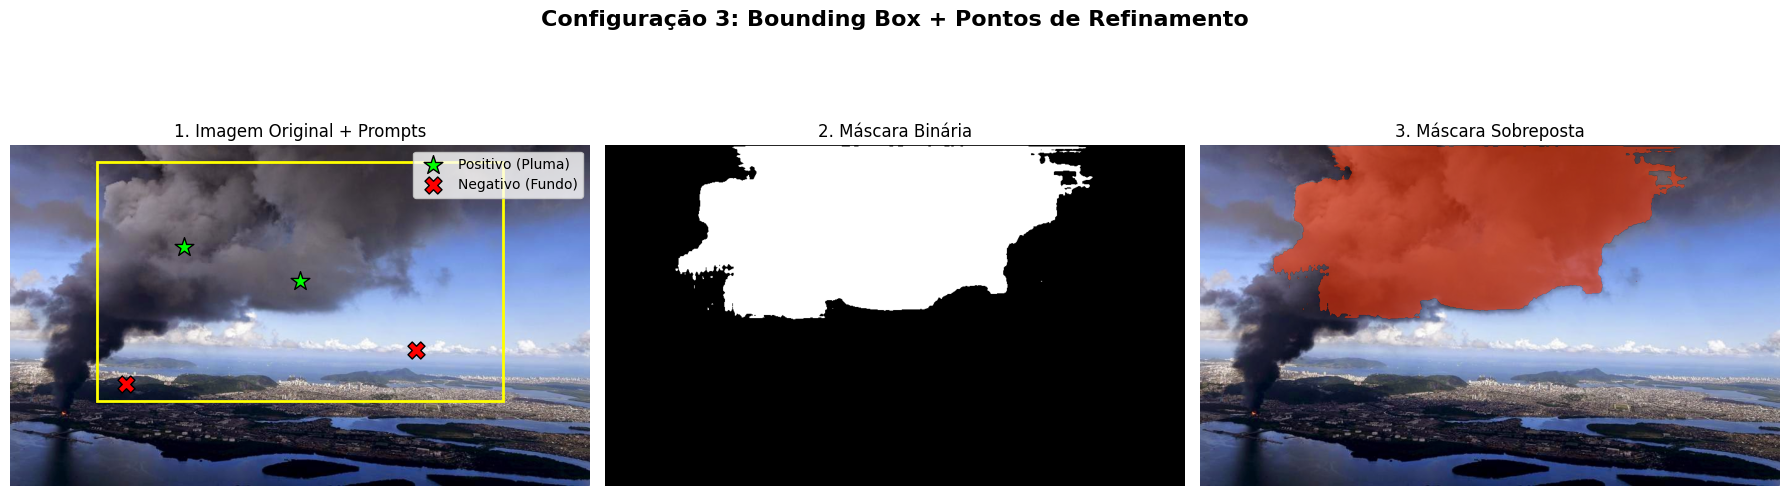

In [ ]:
h, w, _ = image_rgb.shape

# ==============================================================================
# CONFIGURAÇÃO 1: Apenas 1 Ponto Positivo (Centro da pluma)
# ==============================================================================
pts_config1 = np.array([[int(w*0.5), int(h*0.4)]]) # Ajuste (X, Y) para o meio da fumaça
lbl_config1 = np.array([1]) # 1 = Positivo

masks1, scores1, _ = predictor.predict(
    point_coords=pts_config1,
    point_labels=lbl_config1,
    multimask_output=True
)
# Pega a máscara com maior score
melhor_mask1 = masks1[np.argmax(scores1)]
plotar_resultado(image_rgb, melhor_mask1, "Configuração 1: Apenas Ponto Positivo", pts_config1, lbl_config1)


# ==============================================================================
# CONFIGURAÇÃO 2: Múltiplos Pontos Positivos (Pluma) + Negativos (Céu/Nuvens/Prédios)
# ==============================================================================
pts_config2 = np.array([
    [int(w*0.5), int(h*0.4)],  # Positivo: Núcleo denso da pluma
    [int(w*0.3), int(h*0.3)],  # Positivo: Borda/topo da pluma
    [int(w*0.2), int(h*0.70)],  # Negativo: Céu / Nuvens
    [int(w*0.7), int(h*0.60)]  # Negativo: Edifícios / Solo / Tanques
])
lbl_config2 = np.array([1, 1, 0, 0]) # 1 = Pluma, 0 = Fundo a excluir

masks2, scores2, _ = predictor.predict(
    point_coords=pts_config2,
    point_labels=lbl_config2,
    multimask_output=False
)
plotar_resultado(image_rgb, masks2[0], "Configuração 2: Pontos Positivos e Negativos", pts_config2, lbl_config2)


# ==============================================================================
# CONFIGURAÇÃO 3: Caixa Delimitadora (Bounding Box) + Pontos Positivos/Negativos
# ==============================================================================
# Formato da caixa: [x_min, y_min, x_max, y_max] cercando a região da fumaça
box_config3 = np.array([int(w*0.15), int(h*0.05), int(w*0.85), int(h*0.75)])

masks3, scores3, _ = predictor.predict(
    point_coords=pts_config2,
    point_labels=lbl_config2,
    box=box_config3[None, :],
    multimask_output=False
)
plotar_resultado(image_rgb, masks3[0], "Configuração 3: Bounding Box + Pontos de Refinamento", pts_config2, lbl_config2, box_config3)

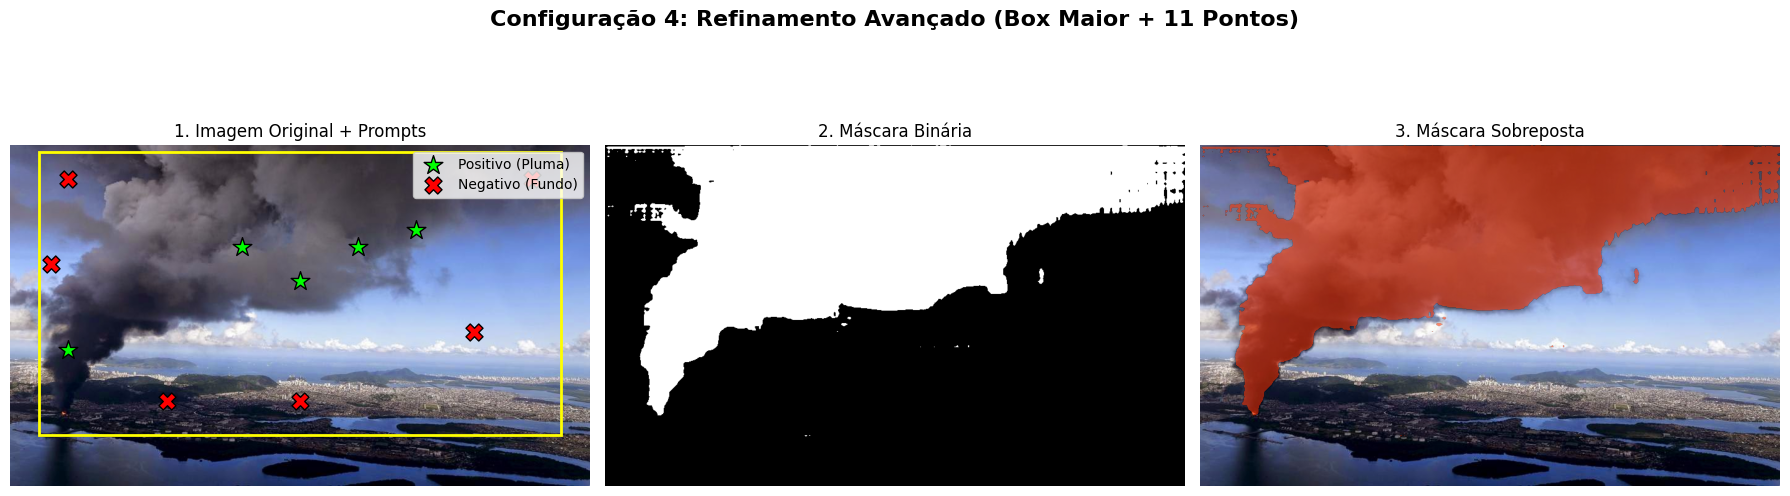

In [ ]:
# ==============================================================================
# CONFIGURAÇÃO 4: Refinamento Avançado (Maior Bounding Box + Mais Pontos)
# ==============================================================================

# Expandindo a caixa delimitadora para pegar quase toda a largura (5% a 95%)
# e descendo até 85% da altura para não cortar a base da pluma.
box_config4 = np.array([int(w*0.05), int(h*0.02), int(w*0.95), int(h*0.85)])

# Múltiplos pontos estratégicos para orientar o SAM
pts_config4 = np.array([
    # --- Pontos POSITIVOS (1) - Fumaça ---
    [int(w*0.50), int(h*0.40)], # Centro do núcleo denso
    [int(w*0.40), int(h*0.30)], # Parte superior esquerda da pluma
    [int(w*0.60), int(h*0.30)], # Parte superior direita da pluma
    [int(w*0.70), int(h*0.25)], # Cauda da fumaça se espalhando à direita
    [int(w*0.10), int(h*0.60)], # Base/origem da fumaça mais escura

    # --- Pontos NEGATIVOS (0) - Fundo (Céu, Nuvens, Solo) ---
    [int(w*0.10), int(h*0.10)], # Céu superior esquerdo
    [int(w*0.90), int(h*0.10)], # Céu superior direito
    [int(w*0.07), int(h*0.35)], # Nuvens/névoa à esquerda
    [int(w*0.50), int(h*0.75)], # Solo/Tanques no centro inferior
    [int(w*0.27), int(h*0.75)], # Cidade/Fundo inferior esquerdo
    [int(w*0.80), int(h*0.55)]  # Cidade/Fundo inferior direito
])

lbl_config4 = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0]) # 1s e 0s correspondentes

# Gerar a predição
masks4, scores4, _ = predictor.predict(
    point_coords=pts_config4,
    point_labels=lbl_config4,
    box=box_config4[None, :],
    multimask_output=False
)

# Plotar o resultado otimizado
plotar_resultado(
    image_rgb,
    masks4[0],
    "Configuração 4: Refinamento Avançado (Box Maior + 11 Pontos)",
    pts_config4,
    lbl_config4,
    box_config4
)

# Relatório de Análise: Detecção e Segmentação de Pluma de Fumaça com SAM

**Disciplina:** Modelagem Computacional — Profa. Raquel Jahara Lobosco  
**Estudo de Caso:** Dispersão da pluma de fumaça do incêndio da Ultracargo (Santos-SP, abril de 2015)  
**Integrantes:**  
* Matheus Oliveira de Jesus — RA 169021  
* Artur de Camargo Santos — RA 170223  

---

## 1. Avaliação Inicial da Máscara Gerada pelo SAM

Na etapa inicial de análise (utilizando segmentação automática ou um prompt mínimo sem refinamento), observou-se o seguinte comportamento do modelo *Segment Anything* (SAM):

* **A máscara cobre toda a pluma?**  
  **Parcialmente.** O modelo consegue identificar com facilidade o núcleo principal e mais denso da coluna de fumaça (próximo à fonte de queima dos tanques de gasolina e etanol, onde a concentração de fuligem é alta). No entanto, à medida que a pluma sofre transporte pelo vento (advecção) e espalhamento turbulento (difusão), a fumaça se torna rarefeita e translúcida, fazendo com que a máscara deixe partes dessas bordas difusas de fora.
* **Inclui regiões que não pertencem a ela?**  
  **Sim.** Na ausência de restrições espaciais e pontos de exclusão, a máscara frequentemente "vaza" para elementos adjacentes da cena, englobando porções do céu, formações de nuvens próximas ao topo da pluma e estruturas escuras na base da imagem (como sombras, edifícios, vegetação da Serra do Mar ou os próprios tanques industriais do terminal portuário).
* **Deixa partes da fumaça de fora?**  
  **Sim.** Especialmente nas zonas periféricas e no topo da pluma, onde a concentração de material particulado diminui gradualmente e a fumaça se mistura visualmente com a atmosfera, o limiar binário do SAM tende a cortar essas regiões de transição.

---

## 2. Desenvolvimento e Justificativa das Melhorias (As 3 Configurações de Prompts)

Para corrigir os problemas de *sub-segmentação* (perda das bordas da fumaça) e *sobre-segmentação* (inclusão de céu, nuvens e edifícios), o código foi aprimorado utilizando o `SamPredictor` com uma visualização lado a lado (**Imagem Original + Prompts | Máscara Binária | Máscara Sobreposta**) em três configurações progressivas:

1. **Configuração 1 — Apenas Ponto Positivo (`label = 1`):**  
   * *Estratégia:* Inserção de um único ponto positivo no centro denso da pluma, utilizando `multimask_output=True` para selecionar a máscara de maior confiança (*score*).
   * *Resultado e Justificativa:* Embora localize a pluma, a falta de contexto de borda faz com que o modelo fique ambíguo entre segmentar apenas o núcleo muito escuro ou expandir excessivamente para o céu ao redor.
2. **Configuração 2 — Pontos Positivos e Negativos (`labels = 1` e `0`):**  
   * *Estratégia:* Adição de múltiplos pontos positivos ao longo do corpo e das bordas da fumaça, combinados com **pontos negativos (`label = 0`)** posicionados estrategicamente sobre o céu, nuvens vizinhas e edifícios/solo na base.
   * *Resultado e Justificativa:* Os pontos negativos atuam como barreiras semânticas, forçando o decodificador do SAM a excluir o fundo urbano e meteorológico, enquanto os pontos positivos extras recuperam regiões menos densas da pluma.
3. **Configuração 3 — Caixa Delimitadora (*Bounding Box*) + Pontos Positivos e Negativos:**  
   * *Estratégia:* Combinação de uma *Bounding Box* (`[x_min, y_min, x_max, y_max]`) cercando estritamente a extensão da pluma com os pontos positivos e negativos de refinamento.
   * *Resultado e Justificativa:* **Apresentou o melhor resultado.** A caixa delimitadora restringe geometricamente a região de interesse (impedindo que objetos distantes com cor similar sejam ativados na máscara), enquanto os pontos internos ajustam com precisão a fronteira entre a fumaça, os prédios e as nuvens.

---

## 3. Características da Imagem que Dificultaram a Segmentação

Diferente de objetos rígidos e sólidos (como carros, prédios ou animais), nos quais o SAM foi extensivamente treinado, uma pluma de fumaça é um **fluido amorfo governado por processos contínuos de advecção-difusão**. As principales dificuldades impostas pela imagem são:

* **Ausência de bordas rígidas (Gradiente Contínuo):** A concentração da fumaça decai suavemente do centro para as bordas. Não existe um contorno físico nítido onde a fumaça "termina" e o ar limpo "começa", tornando difícil para um classificador pixel a pixel definir uma fronteira binária exata.
* **Transparência e Opacidade Variável:** Nas regiões mais diluídas da pluma, os pixels apresentam uma mistura espectral entre a cor da fumaça e a cor do fundo (céu, mar ou relevo ao fundo), confundindo os *embeddings* visuais do modelo.
* **Complexidade do Cenário de Fundo:** Por se tratar de uma região portuária e urbana (Alemoa/Santos), a base da pluma interage visualmente com estruturas industriais, fumaça secundária, sombras e edificações.

---

## 4. Impacto da Iluminação, do Contraste e da Semelhança entre Fumaça e Nuvens

* **Iluminação:** A incidência da luz solar cria variações artificiais de brilho ao longo da própria coluna de fumaça. A face da pluma iluminada diretamente pelo sol torna-se muito mais clara (cinza-claro ou esbranquiçada), enquanto a face sombreada e a base permanecem pretas/escuras. Essa heterogeneidade interna faz com que o SAM, às vezes, interprete a parte iluminada e a parte escura da mesma pluma como dois objetos distintos.
* **Contraste:** Na base do incêndio, a queima incompleta de hidrocarbonetos gera fuligem preta com **altíssimo contraste** em relação ao céu claro, facilitando a detecção. Contudo, nas regiões superiores e periféricas, ou quando o céu ao fundo está nublado/acinzentado, o **baixo contraste** reduz drasticamente o gradiente de intensidade entre a pluma e o fundo, exigindo prompts mais específicos para evitar falhas.
* **Semelhança entre Fumaça e Nuvens:** Tanto as nuvens quanto a fumaça mais dispersa (ou rica em vapor d'água) possuem texturas suaves de baixa frequência espacial, formas orgânicas turbulentas e tons acinzentados/esbranquiçados muito próximos. Sem o uso de **pontos negativos** explicitamente marcados sobre as nuvens e o uso da **caixa delimitadora**, o codificador visual do SAM agrupa nuvens meteorológicas e pluma de poluição como uma única entidade contínua.